# Kokoro step by step — Part 1: token embeddings and an in-between phoneme

This notebook covers:
1. Loading the model and looking inside the two token-embedding tables
2. Checking how phonemes relate to each other in embedding space
3. Creating a new in-between phoneme (e.g. 60 % `t` + 40 % `c`) and giving it its own symbol
4. Running Kokoro as 12 separate steps, so you can stop and intervene anywhere
5. Building a `t` → `c` continuum (acoustic table only, so timing stays identical)
6. Showing that tokens are shared across languages, and the voice carries the language

Tested with kokoro 0.7–0.9. Run the cells top to bottom.

In [1]:

import numpy as np
import torch
import soundfile as sf
import matplotlib.pyplot as plt
from huggingface_hub import hf_hub_download
from kokoro import KModel

device = "cuda" if torch.cuda.is_available() else "cpu"
model = KModel().to(device).eval()   # downloads config.json + weights from hexgrad/Kokoro-82M
SR = 24000                           # Kokoro's sample rate

def load_voice(name):
    """Voice pack = tensor [510, 1, 256]: one 256-number style vector per utterance length."""
    path = hf_hub_download("hexgrad/Kokoro-82M", f"voices/{name}.pt")
    return torch.load(path, weights_only=True).to(device)

pack = load_voice("af_heart")
print("voice pack shape:", tuple(pack.shape))

c:\Users\gmoha\anaconda3\envs\kokoro\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


c:\Users\gmoha\anaconda3\envs\kokoro\Lib\site-packages\torch\nn\modules\rnn.py:1011: UserWarning: dropout option adds dropout after all but last recurrent layer, so non-zero dropout expects num_layers greater than 1, but got dropout=0.2 and num_layers=1
  super().__init__("LSTM", *args, **kwargs)
c:\Users\gmoha\anaconda3\envs\kokoro\Lib\site-packages\torch\nn\utils\weight_norm.py:145: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


voice pack shape: (510, 1, 256)


## 1. The two token-embedding tables

`model.vocab` maps each phoneme **character** to an id (114 symbols in 178 slots).
Each id is a row in **two** tables:

| table | where in the model | shape | decides |
|---|---|---|---|
| `E_pros` | PL-BERT word embeddings | 178 × 128 | durations, pitch, energy |
| `E_ac` | acoustic text encoder | 178 × 512 | what the sound is (spectrum) |

These are *weights of the model*: the same for every voice and every language.

In [2]:
vocab = model.vocab
E_pros = model.bert.embeddings.word_embeddings.weight   # [178, 128]
E_ac   = model.text_encoder.embedding.weight            # [178, 512]
print("prosody table :", tuple(E_pros.shape))
print("acoustic table:", tuple(E_ac.shape))
print("symbols:", "".join(sorted(vocab, key=vocab.get)))

# Note: plain 'g' is NOT in the vocab; Kokoro uses IPA 'ɡ' (U+0261). Anything not in
# the vocab is silently dropped, so always check your strings:
def check(phonemes):
    missing = [p for p in phonemes if p not in vocab]
    if missing:
        print(f"WARNING: {missing} not in vocab and would be dropped")
    return not missing

check("ˈtʲa"), check("ga")

prosody table : (178, 128)
acoustic table: (178, 512)
symbols: ;:,.!?—…"()“” ̃ʣʥʦʨᵝꭧAIOQSTWYᵊabcdefhijklmnopqrstuvwxyzɑɐɒæβɔɕçɖðʤəɚɛɜɟɡɥɨɪʝɯɰŋɳɲɴøɸθœɹɾɻʁɽʂʃʈʧʊʋʌɣɤχʎʒʔˈˌːʰʲ↓→↗↘ᵻ


(True, False)

In [4]:
len(vocab)

114

In [3]:
def vec(sym, table):
    """The embedding vector of one phoneme in one table."""
    return table[vocab[sym]].detach()

print("t, acoustic, first 8 numbers:", vec("t", E_ac)[:8].cpu().numpy().round(3))
print("t, prosody,  first 8 numbers:", vec("t", E_pros)[:8].cpu().numpy().round(3))

t, acoustic, first 8 numbers: [-1.614  0.41   0.71  -0.515  0.388  0.607  0.415 -1.039]
t, prosody,  first 8 numbers: [-0.048  0.188  0.055  0.033 -0.044  0.134  0.023 -0.013]


## 2. How do phonemes relate in embedding space?

Cosine similarity: 1 = same direction, 0 = unrelated. If the space is organised
phonetically, `t` should be closer to `d`, `ʈ` and `c` than to `m` or `a`.

In [5]:
def cos(a, b):
    return torch.nn.functional.cosine_similarity(a, b, dim=0).item()

def similarity_table(symbols, table):
    print("      " + "".join(f"{s:>6}" for s in symbols))
    for s1 in symbols:
        print(f"{s1:>6}" + "".join(f"{cos(vec(s1, table), vec(s2, table)):6.2f}" for s2 in symbols))

def neighbours(sym, table, k=8):
    """The k phonemes whose vectors are most similar to sym."""
    target = vec(sym, table)
    scores = [(s, cos(target, vec(s, table))) for s in vocab if s != sym]
    return sorted(scores, key=lambda x: -x[1])[:k]

similarity_table(["t", "d", "ʈ", "c", "ʨ", "ʧ", "k", "m", "a"], E_ac)
print("\nnearest to t (acoustic):", [(s, round(v, 2)) for s, v in neighbours("t", E_ac)])
print("nearest to c (acoustic):", [(s, round(v, 2)) for s, v in neighbours("c", E_ac)])

           t     d     ʈ     c     ʨ     ʧ     k     m     a
     t  1.00  0.09 -0.00  0.12  0.12 -0.02  0.10  0.01 -0.05
     d  0.09  1.00  0.09  0.01  0.04  0.02  0.06  0.02 -0.05
     ʈ -0.00  0.09  1.00 -0.05  0.04  0.04  0.00  0.10  0.01
     c  0.12  0.01 -0.05  1.00  0.07  0.01 -0.07 -0.01 -0.01
     ʨ  0.12  0.04  0.04  0.07  1.00 -0.04 -0.02 -0.03  0.00
     ʧ -0.02  0.02  0.04  0.01 -0.04  1.00 -0.02 -0.00  0.01
     k  0.10  0.06  0.00 -0.07 -0.02 -0.02  1.00  0.03 -0.04
     m  0.01  0.02  0.10 -0.01 -0.03 -0.00  0.03  1.00 -0.04
     a -0.05 -0.05  0.01 -0.01  0.00  0.01 -0.04 -0.04  1.00

nearest to t (acoustic): [('ʔ', 0.15), ('c', 0.12), ('ʨ', 0.12), ('S', 0.11), ('k', 0.1), ('d', 0.09), ('ʣ', 0.09), ('χ', 0.08)]
nearest to c (acoustic): [('t', 0.12), ('o', 0.09), ('ʂ', 0.09), ('A', 0.09), ('ɟ', 0.08), ('ɹ', 0.07), ('ʨ', 0.07), ('ɖ', 0.06)]


In [11]:
# 1) Length-preserving mix: replace mix_vector in section 3
def mix_vector(mix, table, keep_norm=True):
    v = sum(w * vec(s, table) for s, w in mix.items())
    if keep_norm:
        target = sum(w * vec(s, table).norm() for s, w in mix.items())
        v = v * (target / v.norm())
    return v

# 2) Similarity AFTER the acoustic encoder (step 10), every phoneme in the same frame "ˈ_a"
def contextual_vec(sym, frame="ˈ{}a"):
    ids = step1_tokenize(frame.format(sym))
    t_en = step9_10_acoustic(ids)       # [1, 512, tokens]
    return t_en[0, :, 2]                # position 2 = the consonant (0 = pad, 1 = ˈ)

syms = ["t", "d", "ʈ", "c", "ʨ", "ʧ", "k", "m", "a"]
C = {s: contextual_vec(s) for s in syms}
print("      " + "".join(f"{s:>6}" for s in syms))
for s1 in syms:
    print(f"{s1:>6}" + "".join(f"{cos(C[s1], C[s2]):6.2f}" for s2 in syms))

           t     d     ʈ     c     ʨ     ʧ     k     m     a
     t  1.00  0.89  0.85  0.72  0.76  0.71  0.79  0.61  0.57
     d  0.89  1.00  0.84  0.70  0.71  0.66  0.72  0.66  0.59
     ʈ  0.85  0.84  1.00  0.81  0.83  0.81  0.74  0.60  0.55
     c  0.72  0.70  0.81  1.00  0.98  0.96  0.63  0.53  0.59
     ʨ  0.76  0.71  0.83  0.98  1.00  0.97  0.65  0.53  0.56
     ʧ  0.71  0.66  0.81  0.96  0.97  1.00  0.63  0.50  0.53
     k  0.79  0.72  0.74  0.63  0.65  0.63  1.00  0.65  0.55
     m  0.61  0.66  0.60  0.53  0.53  0.50  0.65  1.00  0.57
     a  0.57  0.59  0.55  0.59  0.56  0.53  0.55  0.57  1.00


**Bonus: is there a consistent "palatalization direction"?**
If the model learned palatality as a direction, the differences
`c−k`, `ɟ−ɡ`, `ɲ−n`, `ʎ−l`, `ç−x`, `ɕ−s` should point the same way
(high cosine between them). If they're near 0, vector arithmetic like
`t + α·direction` won't be meaningful and interpolation is the safer tool.

In [6]:
pairs = [("k", "c"), ("ɡ", "ɟ"), ("n", "ɲ"), ("l", "ʎ"), ("x", "ç"), ("s", "ɕ")]
diffs = {f"{b}-{a}": vec(b, E_ac) - vec(a, E_ac) for a, b in pairs}
names = list(diffs)
print("        " + "".join(f"{n:>7}" for n in names))
for n1 in names:
    print(f"{n1:>7} " + "".join(f"{cos(diffs[n1], diffs[n2]):7.2f}" for n2 in names))
palatal_dir = torch.stack(list(diffs.values())).mean(0)   # keep it for later experiments

            c-k    ɟ-ɡ    ɲ-n    ʎ-l    ç-x    ɕ-s
    c-k    1.00   0.12  -0.02  -0.02   0.02   0.06
    ɟ-ɡ    0.12   1.00   0.06  -0.01  -0.03  -0.01
    ɲ-n   -0.02   0.06   1.00  -0.01   0.09   0.05
    ʎ-l   -0.02  -0.01  -0.01   1.00   0.02   0.12
    ç-x    0.02  -0.03   0.09   0.02   1.00   0.06
    ɕ-s    0.06  -0.01   0.05   0.12   0.06   1.00


## 3. Create an in-between phoneme and give it its own symbol

63 of the 178 rows are unused. We write our new vector into a free row in **both**
tables and register a new single-character symbol for it in `model.vocab`.
After that you can type it in phoneme strings like any other phoneme,
with the stock `model(...)` call and no hooks.

You choose separately what goes in each table:
* `acoustic` mix changes the sound itself
* `prosody` mix changes how the model times / intonates it.
  Keeping it = the base phoneme (`{'t': 1}`) keeps durations identical across a continuum.

In [7]:
CUSTOM = {}   # symbol -> row id, so re-running a cell reuses the same row

def free_rows():
    used = set(vocab.values()) | {0}          # 0 is the padding token
    return [i for i in range(E_ac.shape[0]) if i not in used]

def mix_vector(mix, table):
    """mix = {'t': 0.6, 'c': 0.4}  ->  0.6*t + 0.4*c   (weights need not sum to 1)."""
    return sum(w * vec(s, table) for s, w in mix.items())

@torch.no_grad()
def add_phoneme(symbol, acoustic, prosody=None):
    """Register a new phoneme `symbol` (one Unicode character not already in the vocab).
    acoustic / prosody: dict mixes, or ready-made tensors of size 512 / 128."""
    assert len(symbol) == 1, "Kokoro reads one character = one token"
    assert symbol not in vocab or symbol in CUSTOM, f"{symbol!r} is a real Kokoro phoneme"
    row = CUSTOM.get(symbol) or free_rows()[0]
    prosody = prosody if prosody is not None else acoustic
    E_ac[row]   = acoustic if torch.is_tensor(acoustic) else mix_vector(acoustic, E_ac)
    E_pros[row] = prosody  if torch.is_tensor(prosody)  else mix_vector(prosody, E_pros)
    vocab[symbol] = row
    CUSTOM[symbol] = row
    return row

# A "t" that is 40 % of the way to the palatal stop "c" (sound only; timing of plain t)
row = add_phoneme("Ṭ", acoustic={"t": 0.6, "c": 0.4}, prosody={"t": 1.0})
print("new phoneme Ṭ lives in row", row)
print("cosine to t:", round(cos(vec("Ṭ", E_ac), vec("t", E_ac)), 3),
      "| to c:", round(cos(vec("Ṭ", E_ac), vec("c", E_ac)), 3))

# Quick listen with the stock model call:
torch.manual_seed(0)
audio = model("ˈṬa", pack[len("ˈṬa") - 1])
sf.write("T_mix_quick.wav", audio.numpy(), SR)

new phoneme Ṭ lives in row 7
cosine to t: 0.813 | to c: 0.68


## 4. Kokoro as 12 separate steps

Same numbering as the pipeline map. Each function takes and returns plain tensors,
so between any two steps you can inspect or change the data.
Shapes in comments are for "ˈṬa" (3 symbols → 5 tokens with the two pads).

In [8]:
@torch.no_grad()
def step1_tokenize(phonemes):
    check(phonemes)
    ids = [vocab[p] for p in phonemes if p in vocab]
    return torch.LongTensor([[0, *ids, 0]]).to(device)              # [1, 5]

def step2_voice(pack, phonemes):
    ref_s = pack[len(phonemes) - 1]                                  # [1, 256]
    return ref_s[:, 128:], ref_s[:, :128]                            # prosody style, timbre

@torch.no_grad()
def step3_4_prosody_text(input_ids):
    mask = torch.zeros_like(input_ids, dtype=torch.bool)             # single utterance: no padding
    bert_out = model.bert(input_ids, attention_mask=(~mask).int())   # [1, 5, 768]
    return model.bert_encoder(bert_out).transpose(-1, -2)           # d_en [1, 512, 5]

@torch.no_grad()
def step5_duration_encoder(d_en, style, input_ids):
    L = torch.LongTensor([input_ids.shape[-1]]).to(device)
    mask = torch.zeros_like(input_ids, dtype=torch.bool)
    return model.predictor.text_encoder(d_en, style, L, mask)       # d [1, 5, 640]

@torch.no_grad()
def step6_durations(d, speed=1.0):
    x, _ = model.predictor.lstm(d)
    dur = torch.sigmoid(model.predictor.duration_proj(x)).sum(-1) / speed
    return torch.round(dur).clamp(min=1).long().squeeze(0)          # frames per token [5]

def step7_alignment(pred_dur):
    pred_dur = pred_dur.clamp(min=0)                                 # 0 allowed when you edit it
    T = int(pred_dur.sum())
    aln = torch.zeros(len(pred_dur), T, device=device)
    idx = torch.repeat_interleave(torch.arange(len(pred_dur), device=device), pred_dur.to(device))
    aln[idx, torch.arange(T, device=device)] = 1
    return aln.unsqueeze(0)                                          # [1, 5 tokens, T frames]

@torch.no_grad()
def step8_pitch_energy(d, aln, style):
    en = d.transpose(-1, -2) @ aln                                   # [1, 640, T]
    return model.predictor.F0Ntrain(en, style)                      # F0 [1, 2T], N [1, 2T]

@torch.no_grad()
def step9_10_acoustic(input_ids):
    L = torch.LongTensor([input_ids.shape[-1]]).to(device)
    mask = torch.zeros_like(input_ids, dtype=torch.bool)
    return model.text_encoder(input_ids, L, mask)                    # t_en [1, 512, 5]

def step11_frames(t_en, aln):
    return t_en @ aln                                                # asr [1, 512, T]

@torch.no_grad()
def step12_decode(asr, F0, N, timbre):
    return model.decoder(asr, F0, N, timbre).squeeze().cpu()         # waveform, T*600 samples

def run(phonemes, pack, speed=1.0, pred_dur=None, seed=0, verbose=False):
    """Whole pipeline. Pass pred_dur to force durations (e.g. reuse them across a continuum).
    Returns the audio and every intermediate result, so you can inspect or reuse them."""
    torch.manual_seed(seed)                       # decoder adds random noise -> fix it
    S = {}
    S["ids"] = step1_tokenize(phonemes)
    S["style"], S["timbre"] = step2_voice(pack, phonemes)
    S["d_en"] = step3_4_prosody_text(S["ids"])
    S["d"] = step5_duration_encoder(S["d_en"], S["style"], S["ids"])
    S["pred_dur"] = step6_durations(S["d"], speed) if pred_dur is None else pred_dur
    S["aln"] = step7_alignment(S["pred_dur"])
    S["F0"], S["N"] = step8_pitch_energy(S["d"], S["aln"], S["style"])
    S["t_en"] = step9_10_acoustic(S["ids"])
    S["asr"] = step11_frames(S["t_en"], S["aln"])
    S["audio"] = step12_decode(S["asr"], S["F0"], S["N"], S["timbre"])
    if verbose:
        for k, v in S.items():
            print(f"{k:>9}: {tuple(v.shape)}")
        print("durations (frames):", S["pred_dur"].tolist())
    return S

S = run("ˈṬa", pack, verbose=True)

# Sanity check: identical to Kokoro's own forward pass (same seed)
torch.manual_seed(0)
ref = model("ˈṬa", pack[len("ˈṬa") - 1])
print("matches stock Kokoro:", torch.allclose(S["audio"], ref, atol=1e-4))

      ids: (1, 5)
    style: (1, 128)
   timbre: (1, 128)
     d_en: (1, 512, 5)
        d: (1, 5, 640)
 pred_dur: (5,)
      aln: (1, 5, 54)
       F0: (1, 108)
        N: (1, 108)
     t_en: (1, 512, 5)
      asr: (1, 512, 54)
    audio: (32400,)
durations (frames): [18, 4, 5, 13, 14]
matches stock Kokoro: True


## 5. A `t` → `c` continuum

Only the acoustic table is mixed, and durations are taken from plain `ˈta` and reused,
so every step has exactly the same length, timing and voice row:
only the consonant's spectral identity changes.
Try `TARGET = "ʨ"` too (alveolo-palatal affricate), or `BASE = "k"` for kʲ.

durations used for every step: [18, 4, 5, 13, 14]


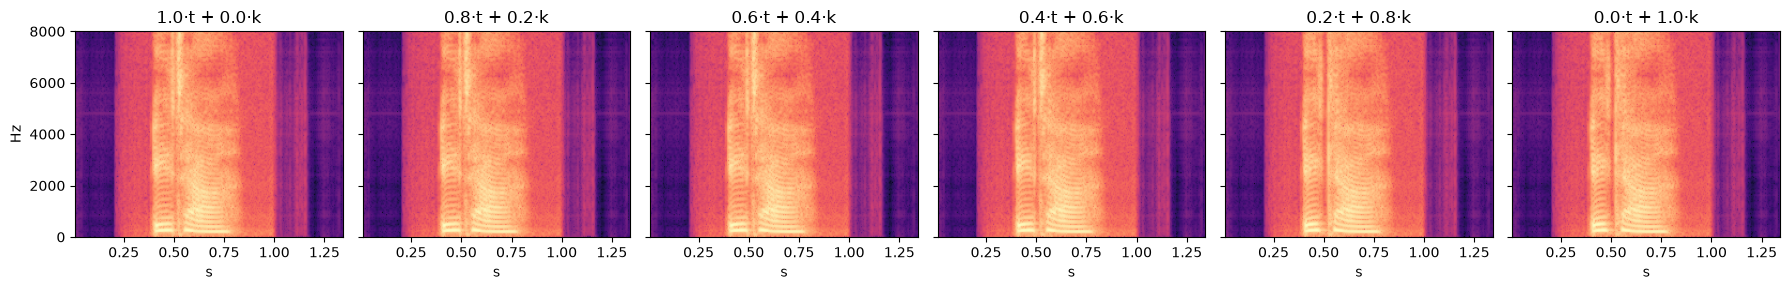

In [10]:
BASE, TARGET = "t", "k"
alphas = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]

base_dur = run(f"ˈ{BASE}a", pack)["pred_dur"]       # timing template
results = {}
for a in alphas:
    add_phoneme("Ṭ", acoustic={BASE: 1 - a, TARGET: a}, prosody={BASE: 1.0})
    S = run("ˈṬa", pack, pred_dur=base_dur)
    results[a] = S["audio"]
    sf.write(f"cont_{BASE}_{TARGET}_{a:.1f}.wav", S["audio"].numpy(), SR)
print("durations used for every step:", base_dur.tolist())

fig, axes = plt.subplots(1, len(alphas), figsize=(3 * len(alphas), 3), sharey=True)
for ax, a in zip(axes, alphas):
    ax.specgram(results[a].numpy(), NFFT=512, Fs=SR, noverlap=384, cmap="magma")
    ax.set_title(f"{1 - a:.1f}·{BASE} + {a:.1f}·{TARGET}")
    ax.set_ylim(0, 8000)
    ax.set_xlabel("s")
axes[0].set_ylabel("Hz")
plt.tight_layout()
plt.savefig("continuum_spectrograms.png", dpi=120)
plt.show()

## 6. Are tokens language-dependent?

No. There is one `t` row, shared by every language. `KModel` is language-blind.
Language differences come from three other places:
1. **G2P**: each language's converter writes different symbols (and context) for the same letter
2. **context**: neighbouring phonemes and stress change the contextual vectors (step 10)
3. **the voice**: voices are trained per language (`af_`/`am_` English, `if_`/`im_` Italian…),
   and the style vector shapes durations, pitch and timbre — e.g. aspiration habits

Same phoneme string, same token vectors, different voices:

In [ ]:
for voice_name in ["af_heart", "if_sara", "im_nicola"]:
    S = run("ˈtata", load_voice(voice_name))
    sf.write(f"tata_{voice_name}.wav", S["audio"].numpy(), SR)
    print(f"{voice_name:>10}: durations {S['pred_dur'].tolist()}")